## Paraller Working

In [12]:

from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langchain_core.tools import tool
from langchain_core.messages import AIMessage, HumanMessage, ToolMessage, SystemMessage
import os

load_dotenv()

if os.environ['OPENAI_API_KEY']:
    print("Openai key is set")
else:
    raise ValueError("openAi key is not set")


llm_openai = ChatOpenAI(model='gpt-5-mini',temperature=0)




Openai key is set


In [13]:
from typing import TypedDict, List
class graph_schema(TypedDict):
    topic : str
    insta:str
    link:str
    yt:str


## Create nodes ##

In [14]:
def create_post_insta(state:graph_schema) -> graph_schema:
    topic = state['topic']
    post = llm_openai.invoke(f"Write an Instagram post about {topic}. Keep the tone casual and engaging.").content
    state['insta']= post
    return {'insta':post}


def create_post_link(state:graph_schema) -> graph_schema:
    topic = state['topic']
    post = llm_openai.invoke(f"Write an Linkedin post about {topic}. Keep the tone casual and engaging.").content
    state['link']= post
    return {'link':post}

def create_post_yt(state:graph_schema) -> graph_schema:
    topic = state['topic']
    post = llm_openai.invoke(f"Write an Youtube post about {topic}. Keep the tone casual and engaging.").content
    state['yt']= post
    return {'yt':post}

## Create State

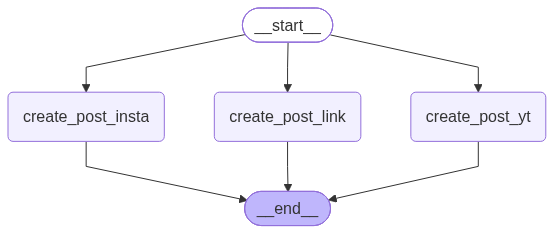

In [15]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)
graph.add_node('create_post_insta',create_post_insta)
graph.add_node('create_post_link',create_post_link)
graph.add_node('create_post_yt',create_post_yt)

graph.add_edge(START,'create_post_insta')
graph.add_edge(START,'create_post_link')
graph.add_edge(START,'create_post_yt')

graph.add_edge('create_post_insta',END)
graph.add_edge('create_post_link',END)
graph.add_edge('create_post_yt',END)

final = graph.compile()

from IPython.display import Image, display
Image(final.get_graph().draw_mermaid_png())



In [16]:
final.invoke({'topic':"Artificial Intelligence",'insta':"","link":"","yt":""})

{'topic': 'Artificial Intelligence',
 'insta': 'AI is everywhere these days — and honestly, it’s kinda wild 🤯✨ From auto-sorting your photos to helping write songs, AI is that behind-the-scenes buddy making life a little easier (and a lot more interesting). It’s great at spotting patterns and automating the boring stuff, but it’s not magic — we still need to use it thoughtfully.  \n\nWhat would you ask an AI to help with today? 👇🤖\n\n#AI #ArtificialIntelligence #Tech #Future #Creativity #EverydayTech',
 'link': 'Remember when “AI” sounded like something only labs and sci-fi movies worried about? Now it’s the quiet teammate helping with meeting notes, first drafts, and endless data wrangling — and honestly, that’s kind of exciting.\n\nA few quick thoughts from the front lines:\n- AI isn’t magic — it’s a productivity boost when paired with human judgment.\n- Small wins matter: automated summaries, smarter search, and time saved on repetitive tasks add up.\n- We still need curiosity, doma